# Análise de Desempenho e Modelo Analítico da API Claude

Este notebook implementa a análise experimental e a validação do modelo analítico descritas em [`docs/plano-estudo.md`](../docs/plano-estudo.md) sobre os dados coletados em [`data/measurements.csv`](../data/measurements.csv).

**Perguntas de pesquisa:**
1. Como o número de tokens de entrada ($n$) e o porte do modelo (`claude-haiku-5-5`, `claude-sonnet-5-5` e `claude-opus-5-5`) afetam a **latência total** e a **vazão efetiva de saída** em requisições sequenciais com resposta curta?
2. Com que precisão o modelo analítico linear $L(n) = \alpha + \beta n + \frac{D}{1000}$, ajustado exclusivamente nos prompts `curto` ($n=458$) e `longo` ($n=6.878$) de cada modelo, prevê a latência do prompt `medio` ($n=1.742$)?

## 1. Configuração e Auditoria dos Controles Experimentais

Carregamos o conjunto de medições e verificamos se todos os controles definidos no desenho experimental foram atendidos:
- **45 chamadas** (`3 modelos × 3 tamanhos × 5 repetições`), todas com `status == 200` e sem erros.
- **Tokens de entrada exatos e consistentes** entre a API `count_tokens` e o retorno de uso: `458` (`curto`), `1.742` (`medio`) e `6.878` (`longo`).
- **Ausência de interferência de cache:** `cache_creation_input_tokens == 0` e `cache_read_input_tokens == 0`.
- **Estabilidade da saída:** `output_tokens == 7` e `stop_reason == "end_turn"` em 100% das chamadas.

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})

MODEL_ORDER = ["claude-haiku-5-5", "claude-sonnet-5-5", "claude-opus-5-5"]
PROMPT_ORDER = ["curto", "medio", "longo"]
MODEL_COLORS = {
    "claude-haiku-5-5": "#2b8cbe",
    "claude-sonnet-5-5": "#e34a33",
    "claude-opus-5-5": "#6a51a3",
}

csv_path = Path("../data/measurements.csv")
if not csv_path.exists():
    csv_path = Path("data/measurements.csv")

df = pd.read_csv(csv_path)
df["timestamp_utc"] = pd.to_datetime(df["timestamp_utc"])
df["model"] = pd.Categorical(df["model"], categories=MODEL_ORDER, ordered=True)
df["prompt"] = pd.Categorical(df["prompt"], categories=PROMPT_ORDER, ordered=True)

# Métricas derivadas conforme docs/plano-estudo.md
df["throughput_tok_s"] = df["output_tokens"] / df["latency_s"]
df["post_ttft_ms"] = (df["latency_s"] - df["ttft_s"]) * 1000.0
df["ttft_share_pct"] = (df["ttft_s"] / df["latency_s"]) * 100.0

# Verificações de integridade dos controles experimentais
assert len(df) == 45, f"Esperadas 45 linhas, encontradas {len(df)}"
assert (df["status"] == 200).all(), "Há chamadas com status diferente de 200"
assert df["error"].isna().all(), "Há erros registrados no CSV"
assert (df["counted_input_tokens"] == df["input_tokens"]).all(), "Divergência entre counted_input_tokens e input_tokens"
assert (df["cache_creation_input_tokens"] == 0).all() and (df["cache_read_input_tokens"] == 0).all(), "Leitura/criação de cache detectada"
assert (df["output_tokens"] == 7).all() and (df["stop_reason"] == "end_turn").all(), "Variação nos tokens de saída ou stop_reason"

controls_summary = pd.DataFrame({
    "Controle": [
        "Total de chamadas medidas",
        "Status HTTP 200 sem erros",
        "Tokens de entrada (curto / médio / longo)",
        "Tokens de saída (output_tokens)",
        "Criações ou leituras de cache",
        "Tempo pós-TTFT médio (latency_s - ttft_s)",
    ],
    "Valor observado": [
        f"{len(df)} (15 por modelo, 5 por tamanho)",
        f"{(df['status'] == 200).sum()}/{len(df)} (100%)",
        f"{sorted(df['input_tokens'].unique().tolist())}",
        f"{df['output_tokens'].unique().tolist()} (stop_reason = end_turn)",
        f"criação={df['cache_creation_input_tokens'].sum()}, leitura={df['cache_read_input_tokens'].sum()}",
        f"{df['post_ttft_ms'].mean():.2f} ms (DP = {df['post_ttft_ms'].std():.2f} ms; TTFT = {df['ttft_share_pct'].mean():.2f}% da latência)",
    ],
})
controls_summary

,Controle,Valor observado
0,Total de chamadas medidas,"45 (15 por modelo, 5 por tamanho)"
1,Status HTTP 200 sem erros,45/45 (100%)
2,Tokens de entrada (curto / médio / longo),"[458, 1742, 6878]"
3,Tokens de saída (output_tokens),[7] (stop_reason = end_turn)
4,Criações ou leituras de cache,"criação=0, leitura=0"
5,Tempo pós-TTFT médio (latency_s - ttft_s),3.81 ms (DP = 1.00 ms; TTFT = 99.63% da latência)


## 2. Estatísticas Descritivas: Latência, TTFT e Vazão Efetiva

Como `output_tokens = 7` é constante e o tempo entre o primeiro `text_delta` (`ttft_s`) e o final da resposta (`latency_s`) é de apenas `~3,8 ms`, **mais de 99,5% da latência total corresponde ao TTFT** (rede, fila e processamento de *prefill* dos tokens de entrada). Consequentemente, a vazão efetiva (`output_tokens / latency_s`) reflete diretamente o inverso da latência total.

In [13]:
desc = (
    df.groupby(["model", "prompt"], observed=True)
    .agg(
        n_tokens=("input_tokens", "first"),
        repeticoes=("latency_s", "count"),
        lat_media_s=("latency_s", "mean"),
        lat_dp_s=("latency_s", "std"),
        lat_min_s=("latency_s", "min"),
        lat_mediana_s=("latency_s", "median"),
        lat_max_s=("latency_s", "max"),
        ttft_medio_s=("ttft_s", "mean"),
        pos_ttft_medio_ms=("post_ttft_ms", "mean"),
        vazao_media_tok_s=("throughput_tok_s", "mean"),
        vazao_dp_tok_s=("throughput_tok_s", "std"),
    )
    .reset_index()
)

desc.round({
    "lat_media_s": 4,
    "lat_dp_s": 4,
    "lat_min_s": 4,
    "lat_mediana_s": 4,
    "lat_max_s": 4,
    "ttft_medio_s": 4,
    "pos_ttft_medio_ms": 2,
    "vazao_media_tok_s": 2,
    "vazao_dp_tok_s": 2,
})

,model,prompt,n_tokens,repeticoes,lat_media_s,lat_dp_s,lat_min_s,lat_mediana_s,lat_max_s,ttft_medio_s,pos_ttft_medio_ms,vazao_media_tok_s,vazao_dp_tok_s
0,claude-haiku-5-5,curto,458,5,0.8208,0.1056,0.7243,0.7824,0.9959,0.8170,3.77,8.63,1.01
1,claude-haiku-5-5,medio,1742,5,0.8813,0.1152,0.7601,0.8940,1.0197,0.8774,3.94,8.05,1.06
2,claude-haiku-5-5,longo,6878,5,0.8585,0.0848,0.7824,0.8386,0.9951,0.8547,3.88,8.21,0.76
3,claude-sonnet-5-5,curto,458,5,0.9281,0.0114,0.9126,0.9269,0.9443,0.9234,4.73,7.54,0.09
4,claude-sonnet-5-5,medio,1742,5,0.9407,0.0374,0.8858,0.9482,0.9887,0.9376,3.13,7.45,0.30
5,claude-sonnet-5-5,longo,6878,5,1.2539,0.0382,1.2031,1.2684,1.2980,1.2503,3.64,5.59,0.17
6,claude-opus-5-5,curto,458,5,1.0369,0.0763,0.9761,0.9872,1.1446,1.0337,3.20,6.78,0.48
7,claude-opus-5-5,medio,1742,5,1.1089,0.0463,1.0611,1.0963,1.1763,1.1054,3.46,6.32,0.26
8,claude-opus-5-5,longo,6878,5,2.0358,0.2202,1.8772,1.9408,2.4172,2.0313,4.54,3.47,0.34


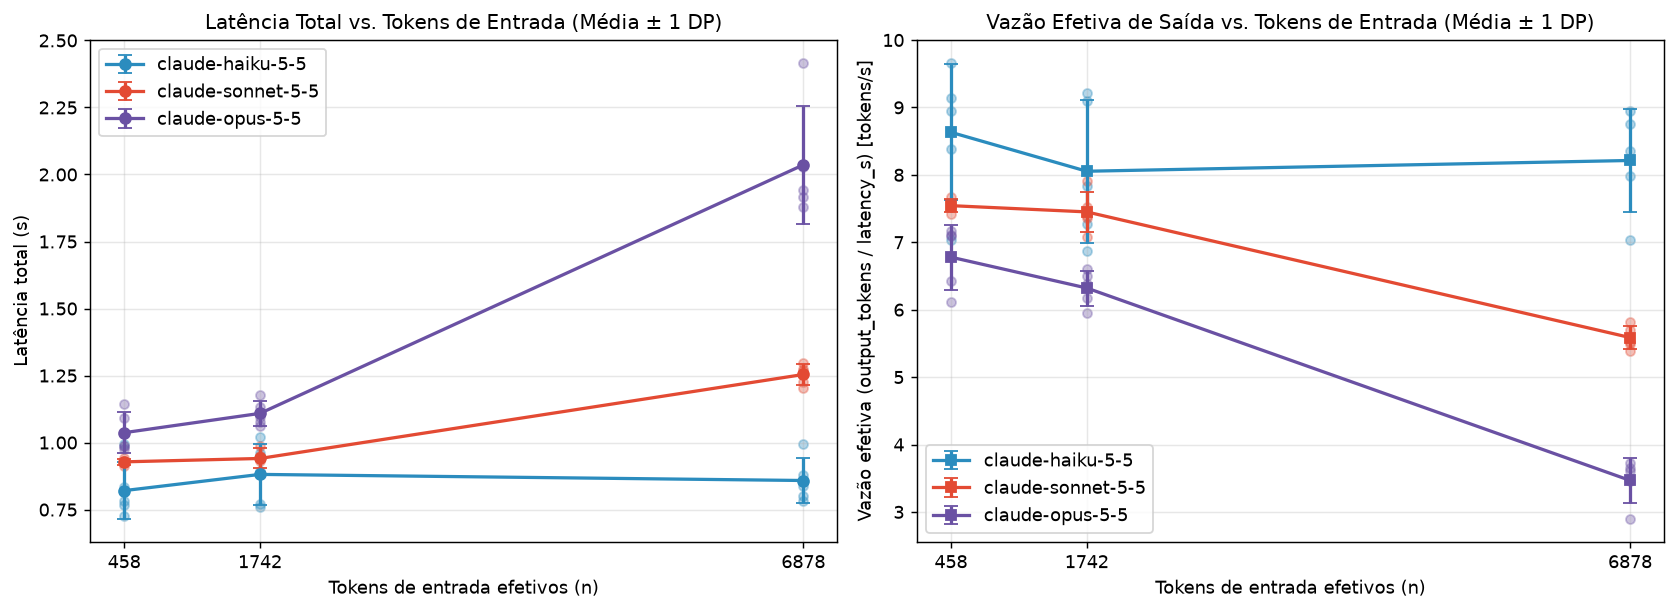

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for model in MODEL_ORDER:
    sub = desc[desc["model"] == model]
    raw = df[df["model"] == model]
    color = MODEL_COLORS[model]

    # Painel 1: Latência Total
    axes[0].errorbar(
        sub["n_tokens"],
        sub["lat_media_s"],
        yerr=sub["lat_dp_s"],
        marker="o",
        linewidth=1.8,
        capsize=4,
        color=color,
        label=model,
    )
    axes[0].scatter(
        raw["input_tokens"],
        raw["latency_s"],
        color=color,
        alpha=0.35,
        s=25,
    )

    # Painel 2: Vazão Efetiva
    axes[1].errorbar(
        sub["n_tokens"],
        sub["vazao_media_tok_s"],
        yerr=sub["vazao_dp_tok_s"],
        marker="s",
        linewidth=1.8,
        capsize=4,
        color=color,
        label=model,
    )
    axes[1].scatter(
        raw["input_tokens"],
        raw["throughput_tok_s"],
        color=color,
        alpha=0.35,
        s=25,
    )

axes[0].set_title("Latência Total vs. Tokens de Entrada (Média ± 1 DP)")
axes[0].set_xlabel("Tokens de entrada efetivos (n)")
axes[0].set_ylabel("Latência total (s)")
axes[0].set_xticks([458, 1742, 6878])
axes[0].legend()

axes[1].set_title("Vazão Efetiva de Saída vs. Tokens de Entrada (Média ± 1 DP)")
axes[1].set_xlabel("Tokens de entrada efetivos (n)")
axes[1].set_ylabel("Vazão efetiva (output_tokens / latency_s) [tokens/s]")
axes[1].set_xticks([458, 1742, 6878])
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Ajuste do Modelo Analítico ($L(n) = \alpha + \beta n + \frac{D}{1000}$)

Conforme definido em [`docs/plano-estudo.md`](../docs/plano-estudo.md):
- Usamos **apenas as repetições dos prompts `curto` ($n=458$) e `longo` ($n=6.878$)** de cada modelo (10 observações por modelo) para estimar $\alpha$ (parcela fixa, em segundos) e $\beta$ (tempo adicional por token de entrada, em segundos por token).
- O maior desvio absoluto observado nos pontos de treino em relação à reta ajustada define a escala de variação aleatória $D_{\max}$ (convertida para milissegundos):
  $$D_{\max} = 1000 \times \max_{i \in \text{treino}} \left| L_i - (\alpha + \beta n_i) \right|$$

In [15]:
model_params = []

for model in MODEL_ORDER:
    m_df = df[df["model"] == model]
    train_df = m_df[m_df["prompt"].isin(["curto", "longo"])].copy()
    val_df = m_df[m_df["prompt"] == "medio"].copy()

    # Ajuste linear OLS em curto (n=458) e longo (n=6878)
    x_train = train_df["input_tokens"].to_numpy(dtype=float)
    y_train = train_df["latency_s"].to_numpy(dtype=float)
    beta, alpha = np.polyfit(x_train, y_train, 1)

    # Predições e resíduos no conjunto de treino
    y_train_pred = alpha + beta * x_train
    train_residuals_s = y_train - y_train_pred
    max_dev_s = float(np.max(np.abs(train_residuals_s)))
    d_max_ms = max_dev_s * 1000.0

    # R² no conjunto de treino
    ss_res_train = float(np.sum(train_residuals_s ** 2))
    ss_tot_train = float(np.sum((y_train - np.mean(y_train)) ** 2))
    r2_train = 1.0 - (ss_res_train / ss_tot_train)

    # Validação no prompt médio (n=1742)
    n_medio = float(val_df["input_tokens"].iloc[0])
    pred_medio_s = float(alpha + beta * n_medio)
    meas_medio_mean_s = float(val_df["latency_s"].mean())
    meas_medio_sd_s = float(val_df["latency_s"].std())

    diff_s = pred_medio_s - meas_medio_mean_s
    abs_diff_s = abs(diff_s)
    diff_pct = (diff_s / meas_medio_mean_s) * 100.0
    abs_diff_pct = abs(diff_pct)

    # Quantas repetições de 'medio' caem dentro da faixa [pred - D_max/1000, pred + D_max/1000]
    in_band = int(((val_df["latency_s"] >= pred_medio_s - max_dev_s) & (val_df["latency_s"] <= pred_medio_s + max_dev_s)).sum())

    model_params.append({
        "model": model,
        "alpha_s": alpha,
        "beta_s_per_tok": beta,
        "beta_ms_per_1k_tok": beta * 1e6 / 1000.0,  # ms por 1.000 tokens (= µs/token)
        "beta_us_per_tok": beta * 1e6,
        "D_max_ms": d_max_ms,
        "R2_treino": r2_train,
        "pred_medio_s": pred_medio_s,
        "medido_medio_s": meas_medio_mean_s,
        "dp_medio_s": meas_medio_sd_s,
        "erro_s (pred - med)": diff_s,
        "erro_abs_s": abs_diff_s,
        "erro_pct (%)": diff_pct,
        "erro_abs_pct (%)": abs_diff_pct,
        "faixa_medio_min_s": pred_medio_s - max_dev_s,
        "faixa_medio_max_s": pred_medio_s + max_dev_s,
        "medio_na_faixa_D": f"{in_band}/{len(val_df)}",
    })

params_df = pd.DataFrame(model_params)
params_df[[
    "model", "alpha_s", "beta_us_per_tok", "D_max_ms", "R2_treino",
    "pred_medio_s", "medido_medio_s", "erro_s (pred - med)", "erro_pct (%)", "medio_na_faixa_D"
]].round({
    "alpha_s": 4,
    "beta_us_per_tok": 2,
    "D_max_ms": 2,
    "R2_treino": 4,
    "pred_medio_s": 4,
    "medido_medio_s": 4,
    "erro_s (pred - med)": 4,
    "erro_pct (%)": 2,
})

,model,alpha_s,beta_us_per_tok,D_max_ms,R2_treino,pred_medio_s,medido_medio_s,erro_s (pred - med),erro_pct (%),medio_na_faixa_D
0,claude-haiku-5-5,0.8181,5.88,175.10,0.0463,0.8283,0.8813,-0.0530,-6.01,4/5
1,claude-sonnet-5-5,0.9049,50.76,50.86,0.9766,0.9933,0.9407,0.0525,5.58,3/5
2,claude-opus-5-5,0.9656,155.60,381.35,0.9199,1.2367,1.1089,0.1278,11.52,5/5


## 4. Validação Detalhada no Prompt Médio ($n = 1.742$) e Cenários de $D$

Abaixo inspecionamos cada uma das 5 chamadas individuais do prompt `medio` ($n = 1.742$) frente à previsão linear $\hat{L}(1.742)$ e à faixa ilustrativa $\hat{L}(1.742) \pm \frac{D_{\max}}{1000}$, além de sortearmos cenários uniformes $D \sim \mathcal{U}(-D_{\max}, +D_{\max})$ conforme descrito no plano.

In [16]:
# Tabela das medições individuais do prompt médio vs. previsão linear
medio_rows = df[df["prompt"] == "medio"].merge(
    params_df[["model", "pred_medio_s", "D_max_ms"]],
    on="model",
    how="left",
)
medio_rows = medio_rows.rename(columns={"pred_medio_s": "pred_linear_s"})
medio_rows["desvio_ms"] = (medio_rows["latency_s"] - medio_rows["pred_linear_s"]) * 1000.0
medio_rows["dentro_faixa_D"] = medio_rows["desvio_ms"].abs() <= medio_rows["D_max_ms"]

medio_rows[[
    "model", "repetition", "input_tokens", "latency_s", "pred_linear_s",
    "desvio_ms", "D_max_ms", "dentro_faixa_D"
]].round({
    "latency_s": 4,
    "pred_linear_s": 4,
    "desvio_ms": 2,
    "D_max_ms": 2,
})

,model,repetition,input_tokens,latency_s,pred_linear_s,desvio_ms,D_max_ms,dentro_faixa_D
0,claude-haiku-5-5,1,1742,0.9630,0.8283,134.62,175.10,True
1,claude-haiku-5-5,2,1742,0.7601,0.8283,-68.28,175.10,True
2,claude-haiku-5-5,3,1742,0.7698,0.8283,-58.51,175.10,True
3,claude-haiku-5-5,4,1742,0.8940,0.8283,65.62,175.10,True
4,claude-haiku-5-5,5,1742,1.0197,0.8283,191.38,175.10,False
5,claude-sonnet-5-5,1,1742,0.9482,0.9933,-45.05,50.86,True
6,claude-sonnet-5-5,2,1742,0.8858,0.9933,-107.42,50.86,False
7,claude-sonnet-5-5,3,1742,0.9887,0.9933,-4.56,50.86,True
8,claude-sonnet-5-5,4,1742,0.9301,0.9933,-63.16,50.86,False
9,claude-sonnet-5-5,5,1742,0.9508,0.9933,-42.43,50.86,True


In [17]:
# Sorteio uniforme ilustrativo de cenários D ~ U(-D_max, +D_max) para n = 1.742
rng = np.random.default_rng(42)
scenarios = []

for row in model_params:
    m = row["model"]
    d_draws = rng.uniform(-row["D_max_ms"], row["D_max_ms"], size=5)
    sim_latencies = row["pred_medio_s"] + d_draws / 1000.0
    scenarios.append({
        "model": m,
        "L_hat(1742) [s]": round(row["pred_medio_s"], 4),
        "Faixa [L_hat ± D_max/1000] [s]": f"[{row['faixa_medio_min_s']:.4f}, {row['faixa_medio_max_s']:.4f}]",
        "5 sorteios D (ms)": [round(float(x), 1) for x in d_draws],
        "5 latências simuladas L(1742) [s]": [round(float(x), 4) for x in sim_latencies],
        "5 latências reais medidas [s]": [
            round(float(x), 4)
            for x in df[(df["model"] == m) & (df["prompt"] == "medio")]["latency_s"]
        ],
    })

pd.DataFrame(scenarios)

,model,L_hat(1742) [s],Faixa [L_hat ± D_max/1000] [s],5 sorteios D (ms),5 latências simuladas L(1742) [s],5 latências reais medidas [s]
0,claude-haiku-5-5,0.8283,"[0.6532, 1.0034]","[95.9, -21.4, 125.6, 69.1, -142.1]","[0.9243, 0.8069, 0.9539, 0.8975, 0.6862]","[0.963, 0.7601, 0.7698, 0.894, 1.0197]"
1,claude-sonnet-5-5,0.9933,"[0.9424, 1.0441]","[48.4, 26.6, 29.1, -37.8, -5.0]","[1.0416, 1.0198, 1.0224, 0.9554, 0.9882]","[0.9482, 0.8858, 0.9887, 0.9301, 0.9508]"
2,claude-opus-5-5,1.2367,"[0.8553, 1.6180]","[-98.5, 325.5, 109.7, 246.2, -43.2]","[1.1381, 1.5622, 1.3464, 1.4828, 1.1935]","[1.0963, 1.0611, 1.1763, 1.0773, 1.1335]"


## 5. Visualização do Modelo Analítico vs. Medições

Os gráficos abaixo mostram, para cada modelo:
- Os pontos individuais de treino (`curto` e `longo`) que definem a reta $\alpha + \beta n$.
- A faixa sombreada $\alpha + \beta n \pm D_{\max}/1000$.
- As medições reais de validação no prompt `medio` ($n = 1.742$) e a respectiva média medida comparada à previsão linear.

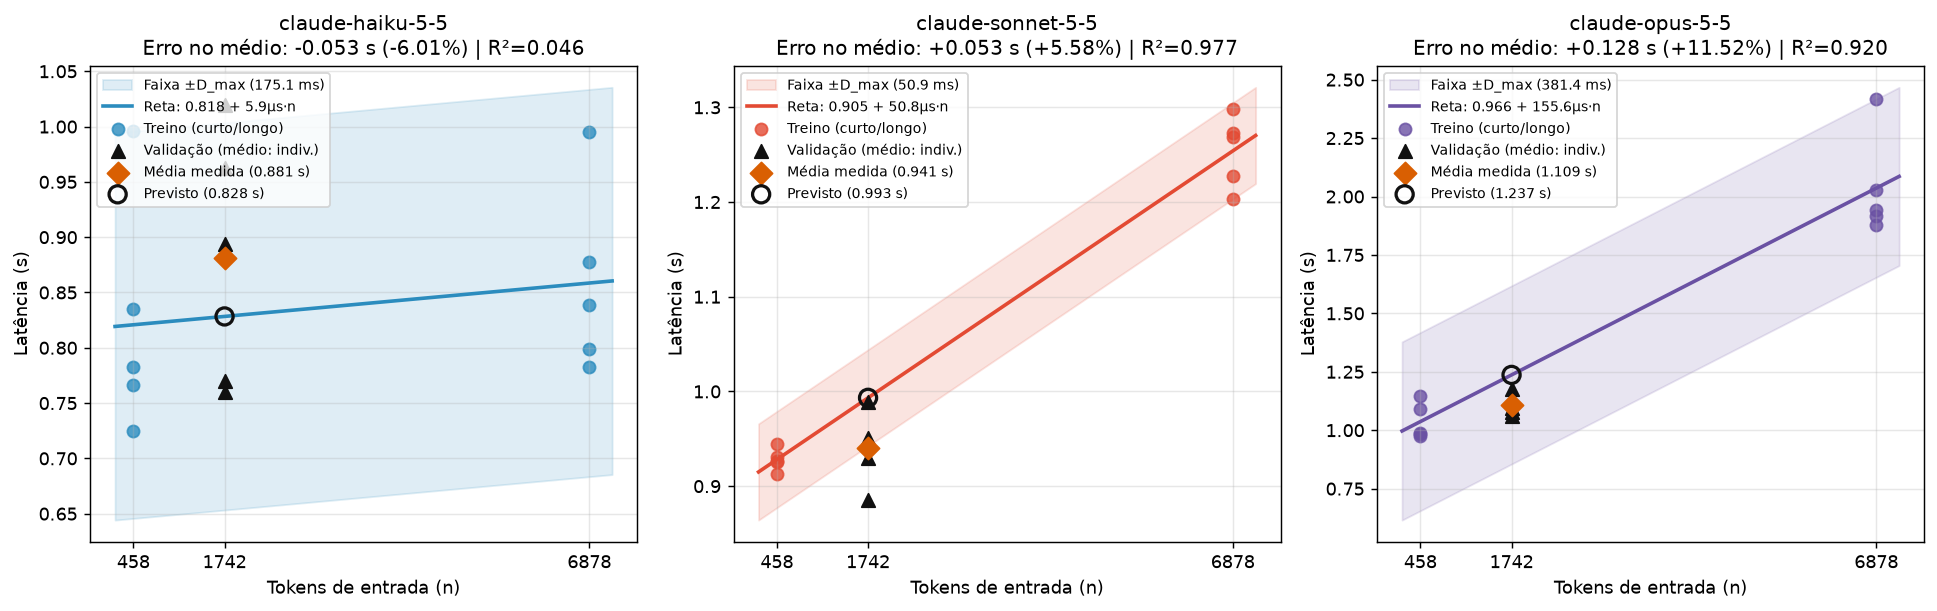

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=False)
x_grid = np.linspace(200, 7200, 200)

for ax, row in zip(axes, model_params):
    model = row["model"]
    color = MODEL_COLORS[model]
    m_df = df[df["model"] == model]
    train_df = m_df[m_df["prompt"].isin(["curto", "longo"])]
    val_df = m_df[m_df["prompt"] == "medio"]

    y_line = row["alpha_s"] + row["beta_s_per_tok"] * x_grid
    d_sec = row["D_max_ms"] / 1000.0

    # Faixa ± D_max / 1000
    ax.fill_between(
        x_grid,
        y_line - d_sec,
        y_line + d_sec,
        color=color,
        alpha=0.15,
        label=f"Faixa ±D_max ({row['D_max_ms']:.1f} ms)",
    )
    # Reta ajustada
    ax.plot(
        x_grid,
        y_line,
        color=color,
        linewidth=2.0,
        label=f"Reta: {row['alpha_s']:.3f} + {row['beta_us_per_tok']:.1f}µs·n",
    )

    # Pontos de treino
    ax.scatter(
        train_df["input_tokens"],
        train_df["latency_s"],
        color=color,
        marker="o",
        s=45,
        alpha=0.8,
        label="Treino (curto/longo)",
    )

    # Pontos de validação (médio)
    ax.scatter(
        val_df["input_tokens"],
        val_df["latency_s"],
        color="#111111",
        marker="^",
        s=55,
        zorder=5,
        label="Validação (médio: indiv.)",
    )

    # Média medida vs. Previsão em n = 1742
    ax.scatter(
        [1742],
        [row["medido_medio_s"]],
        color="#d95f02",
        marker="D",
        s=75,
        zorder=6,
        label=f"Média medida ({row['medido_medio_s']:.3f} s)",
    )
    ax.scatter(
        [1742],
        [row["pred_medio_s"]],
        facecolors="none",
        edgecolors="#111111",
        marker="o",
        s=90,
        linewidth=1.8,
        zorder=6,
        label=f"Previsto ({row['pred_medio_s']:.3f} s)",
    )

    ax.set_title(
        f"{model}\nErro no médio: {row['erro_s (pred - med)']:+.3f} s ({row['erro_pct (%)']:+.2f}%) | R²={row['R2_treino']:.3f}"
    )
    ax.set_xlabel("Tokens de entrada (n)")
    ax.set_ylabel("Latência (s)")
    ax.set_xticks([458, 1742, 6878])
    ax.legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()

## 6. Ordem de Execução e Sensibilidade a Outliers

Inspecionamos a série temporal das 45 chamadas para verificar se houve deriva de rede/fila ao longo da coleta e avaliamos o impacto do outlier observado na 5ª repetição do prompt `longo` no `claude-opus-5-5` (`2,417 s` contra `~1,94 s` nas 4 repetições anteriores).

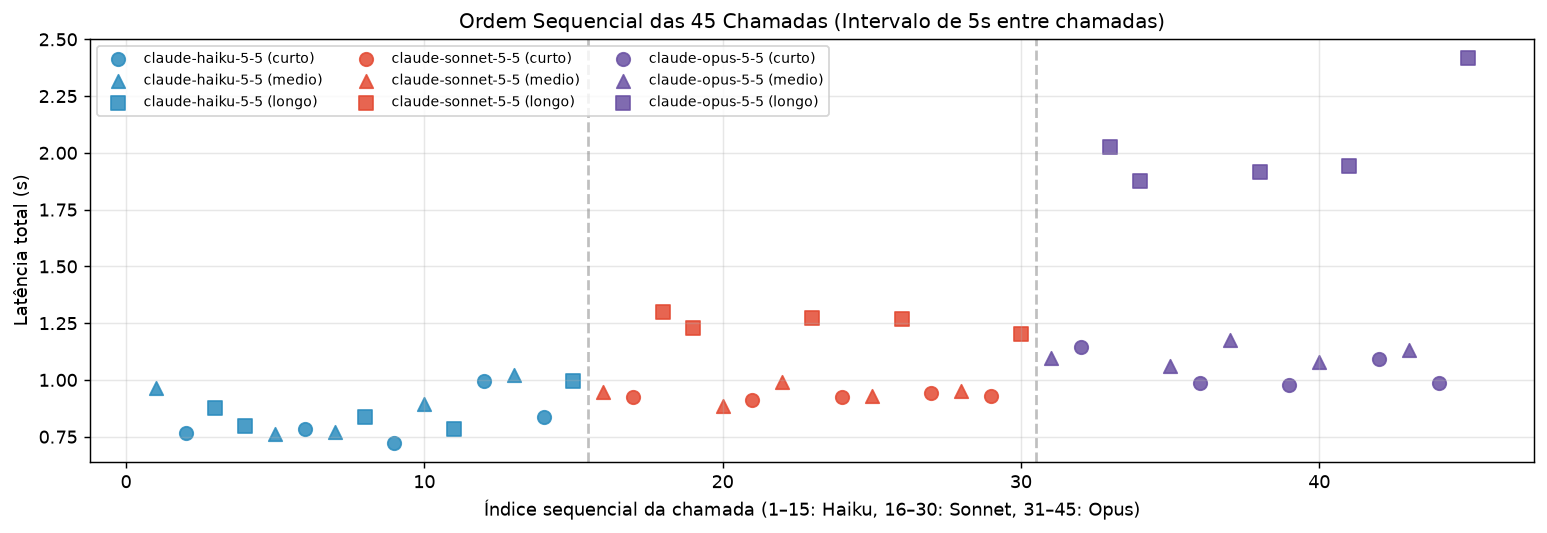

In [19]:
fig, ax = plt.subplots(figsize=(12, 4.2))

df_sorted = df.sort_values("timestamp_utc").reset_index(drop=True)
df_sorted["call_order"] = df_sorted.index + 1

markers = {"curto": "o", "medio": "^", "longo": "s"}
for model in MODEL_ORDER:
    for prompt in PROMPT_ORDER:
        sub = df_sorted[(df_sorted["model"] == model) & (df_sorted["prompt"] == prompt)]
        ax.scatter(
            sub["call_order"],
            sub["latency_s"],
            color=MODEL_COLORS[model],
            marker=markers[prompt],
            s=55,
            alpha=0.85,
            label=f"{model} ({prompt})",
        )

ax.axvline(15.5, color="gray", linestyle="--", alpha=0.5)
ax.axvline(30.5, color="gray", linestyle="--", alpha=0.5)
ax.set_title("Ordem Sequencial das 45 Chamadas (Intervalo de 5s entre chamadas)")
ax.set_xlabel("Índice sequencial da chamada (1–15: Haiku, 16–30: Sonnet, 31–45: Opus)")
ax.set_ylabel("Latência total (s)")
ax.legend(ncol=3, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

In [20]:
# Análise de sensibilidade: ajuste do claude-opus-5-5 sem o pico da repetição 5 do prompt longo (2,417 s)
opus_df = df[df["model"] == "claude-opus-5-5"]
opus_train_no_outlier = opus_df[
    (opus_df["prompt"] == "curto") | ((opus_df["prompt"] == "longo") & (opus_df["repetition"] < 5))
]

beta_no_out, alpha_no_out = np.polyfit(
    opus_train_no_outlier["input_tokens"].to_numpy(dtype=float),
    opus_train_no_outlier["latency_s"].to_numpy(dtype=float),
    1,
)
pred_medio_no_out = float(alpha_no_out + beta_no_out * 1742.0)
meas_medio_opus = float(opus_df[opus_df["prompt"] == "medio"]["latency_s"].mean())
max_dev_no_out_ms = float(
    np.max(np.abs(opus_train_no_outlier["latency_s"] - (alpha_no_out + beta_no_out * opus_train_no_outlier["input_tokens"])))
) * 1000.0

opus_Full = params_df[params_df["model"] == "claude-opus-5-5"].iloc[0]

pd.DataFrame([
    {
        "Cenário (claude-opus-5-5)": "Completo (todas as 10 repetições de treino)",
        "alpha (s)": round(float(opus_Full["alpha_s"]), 4),
        "beta (µs/token)": round(float(opus_Full["beta_us_per_tok"]), 2),
        "D_max (ms)": round(float(opus_Full["D_max_ms"]), 2),
        "Previsto médio (s)": round(float(opus_Full["pred_medio_s"]), 4),
        "Medido médio (s)": round(meas_medio_opus, 4),
        "Erro (%)": round(float(opus_Full["erro_pct (%)"]), 2),
    },
    {
        "Cenário (claude-opus-5-5)": "Sem outlier (excluindo longo rep 5 = 2,417 s)",
        "alpha (s)": round(float(alpha_no_out), 4),
        "beta (µs/token)": round(float(beta_no_out * 1e6), 2),
        "D_max (ms)": round(max_dev_no_out_ms, 2),
        "Previsto médio (s)": round(pred_medio_no_out, 4),
        "Medido médio (s)": round(meas_medio_opus, 4),
        "Erro (%)": round(((pred_medio_no_out - meas_medio_opus) / meas_medio_opus) * 100.0, 2),
    },
])

,Cenário (claude-opus-5-5),alpha (s),beta (µs/token),D_max (ms),Previsto médio (s),Medido médio (s),Erro (%)
0,Completo (todas as 10 repetições de treino),0.9656,155.60,381.35,1.2367,1.1089,11.52
1,"Sem outlier (excluindo longo rep 5 = 2,417 s)",0.9724,140.75,107.75,1.2176,1.1089,9.80


## 7. Contabilização de Tokens, Custo Estimado e Conclusões

Aplicamos a equação de custo de [`docs/plano-estudo.md`](../docs/plano-estudo.md):
$$C \approx \frac{\sum_{i=1}^{N} (n_i p_{\text{entrada}} + o_i p_{\text{saída}})}{10^6}$$
usando as tarifas de referência por milhão de tokens das três classes de modelos (Haiku: US\$ 1 / US\$ 5; Sonnet: US\$ 3 / US\$ 15; Opus: US\$ 5 / US\$ 25).

In [21]:
# Tarifas de referência em US$ por 1 milhão de tokens (entrada / saída)
PRICING_USD_PER_MTOK = {
    "claude-haiku-5-5": (1.00, 5.00),
    "claude-sonnet-5-5": (3.00, 15.00),
    "claude-opus-5-5": (5.00, 25.00),
}

cost_rows = []
for model in MODEL_ORDER:
    sub = df[df["model"] == model]
    in_tok = int(sub["input_tokens"].sum())
    out_tok = int(sub["output_tokens"].sum())
    p_in, p_out = PRICING_USD_PER_MTOK[model]
    cost_usd = (in_tok * p_in + out_tok * p_out) / 1e6
    cost_rows.append({
        "Modelo": model,
        "Chamadas": len(sub),
        "Tokens de entrada totais": in_tok,
        "Tokens de saída totais": out_tok,
        "Preço entrada ($/MTok)": p_in,
        "Preço saída ($/MTok)": p_out,
        "Custo estimado (US$)": round(cost_usd, 4),
    })

cost_df = pd.DataFrame(cost_rows)
total_row = pd.DataFrame([{
    "Modelo": "TOTAL",
    "Chamadas": int(cost_df["Chamadas"].sum()),
    "Tokens de entrada totais": int(cost_df["Tokens de entrada totais"].sum()),
    "Tokens de saída totais": int(cost_df["Tokens de saída totais"].sum()),
    "Preço entrada ($/MTok)": np.nan,
    "Preço saída ($/MTok)": np.nan,
    "Custo estimado (US$)": round(float(cost_df["Custo estimado (US$)"].sum()), 4),
}])
pd.concat([cost_df, total_row], ignore_index=True)

,Modelo,Chamadas,Tokens de entrada totais,Tokens de saída totais,Preço entrada ($/MTok),Preço saída ($/MTok),Custo estimado (US$)
0,claude-haiku-5-5,15,45390,105,1.0,5.0,0.0459
1,claude-sonnet-5-5,15,45390,105,3.0,15.0,0.1377
2,claude-opus-5-5,15,45390,105,5.0,25.0,0.2296
3,TOTAL,45,136170,315,NaN,NaN,0.4132


### Síntese das Conclusões

1. **Efeito dos tokens de entrada ($n$) na latência e na vazão efetiva:**
   - Como a resposta curta foi rigorosamente constante (`7` tokens, `~3,8 ms` pós-TTFT), a latência total é determinada quase integralmente pelo **TTFT** (>99,5%).
   - No **`claude-haiku-5-5`**, o custo marginal por token de entrada é muito baixo ($\beta \approx 5{,}88\text{ }\mu\text{s/token}$), aumentando a latência média em apenas `~38 ms` entre `458` e `6.878` tokens (`0,821 s` $\to$ `0,859 s`). Por isso, a vazão efetiva permanece estável (`8,63` $\to$ `8,21 tokens/s`) e a variação aleatória de rede/fila ($D_{\max} = \pm 175{,}1\text{ ms}$) domina o comportamento ($R^2 = 0{,}046$).
   - No **`claude-sonnet-5-5`** ($\beta \approx 50{,}76\text{ }\mu\text{s/token}$, $R^2 = 0{,}977$) e no **`claude-opus-5-5`** ($\beta \approx 155{,}60\text{ }\mu\text{s/token}$, $R^2 = 0{,}920$), o tempo de *prefill* cresce fortemente com $n$, elevando a latência (`0,928 s` $\to$ `1,254 s` no Sonnet; `1,037 s` $\to$ `2,036 s` no Opus) e reduzindo a vazão efetiva (`7,54` $\to$ `5,59 tokens/s` no Sonnet; `6,78` $\to$ `3,47 tokens/s` no Opus).

2. **Precisão do modelo analítico linear no ponto de interpolação (`medio`, $n = 1.742$):**
   - **Haiku 5.5:** previu `0,8283 s` vs. média medida de `0,8813 s` (diferença de `-0,0530 s` ou **-6,01%**), com **4 de 5** observações dentro de $\hat{L} \pm D_{\max}/1000$.
   - **Sonnet 5.5:** previu `0,9933 s` vs. média medida de `0,9407 s` (diferença de `+0,0525 s` ou **+5,58%**), com **3 de 5** observações dentro da faixa estrita de $\pm 50{,}9\text{ ms}$.
   - **Opus 5.5:** previu `1,2367 s` vs. média medida de `1,1089 s` (diferença de `+0,1278 s` ou **+11,52%**; ou **+9,54%** ao remover o outlier de `2,417 s` do treino), com **5 de 5** observações dentro de $\hat{L} \pm D_{\max}/1000$.
   - Tanto no Sonnet quanto no Opus, a reta ajustada nos extremos superestima ligeiramente o ponto intermediário `medio`, indicando que o processamento em lote (*prefill*) entre `458` e `1.742` tokens aproveita melhor o paralelismo do hardware remoto do que na faixa até `6.878` tokens.